# Two-pion test II: Gaussian noise and the HLT error budget

Repeat the withheld-time reconstruction from
[the exact-data notebook](01_two_pion_exact.ipynb), now with a seeded
Gaussian fluctuation of the input correlator. Plot the R ratio and
correlator, scan the same lambdas, compute the systematic envelope, and
compare it with the propagated statistical uncertainty.

This notebook is self-contained; run its cells from top to bottom.
Installation and execution instructions are in [README.md](README.md).
All HLT solves and model integrals use 50 decimal digits. Random draws,
Monte Carlo checks, and plotting use binary64.

In [1]:
from dataclasses import replace
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

# Use this checkout whether Jupyter starts in the root or in notebooks/.
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src" / "spectral" / "__init__.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter in the spectRAL checkout or notebooks/.")
sys.path.insert(0, str(ROOT / "src"))

import spectral as sp  # noqa: E402 -- import after locating this checkout
from spectral.algorithms import hlt  # noqa: E402

%matplotlib inline
plt.rcParams.update({
    "figure.figsize": (10, 4),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})


def show_table(headers, rows):
    '''Small notebook table without an additional pandas dependency.'''
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

## 1. Two-pion model and Euclidean correlator

The supplied `TwoPionModel` is a rho-dominance **toy model for the two-pion
contribution**, not the complete experimental hadronic R ratio. Above threshold,

$$
R_{\pi\pi}(s)=\frac14\beta_\pi(s)^3 |F_\pi(s)|^2,\qquad
\beta_\pi(s)=\sqrt{1-\frac{4m_\pi^2}{s}},
$$
$$
|F_\pi(s)|^2=
\frac{m_\rho^4}{(m_\rho^2-s)^2+s\Gamma(s)^2},\qquad
\Gamma(s)=\Gamma_\rho\frac{m_\rho}{\sqrt{s}}
\left[\frac{\beta_\pi(s)}{\beta_\pi(m_\rho^2)}\right]^3.
$$

It is zero for $\sqrt{s}\leq 2m_\pi$. The parameters are
$m_\pi=0.13957039$, $m_\rho=0.77526$, and $\Gamma_\rho=0.1491$, all in GeV.
We use the infinite-time exponential kernel (no periodic backward term):

$$
C(t)=\int_{2m_\pi}^{\infty}
\frac{\omega^2 R_{\pi\pi}(\omega^2)}{12\pi^2}e^{-\omega t}\,d\omega.
$$

Energies are in GeV, times in $\mathrm{GeV}^{-1}$, and $C$ in
$\mathrm{GeV}^3$. With the library's choice $p=2$,
$\rho_2(\omega)=R_{\pi\pi}(\omega^2)/(12\pi^2)$ and
$\phi_t(\omega)=\omega^2e^{-\omega t}$, so $C(t)=\int\rho_2\phi_t$.
The plot's energy range does **not** truncate the correlator integrals.

In [2]:
INPUT_TIMES = np.arange(1,10)  # GeV^{-1}
TARGET_TIME = 15             # GeV^{-1}; deliberately absent from the input
LAMBDAS = (
    "0", "1e-14","1e-12", "1e-10", "1e-8", "1e-6", "1e-5",
    "1e-4", "3e-4", "1e-3", "1e-2", "1e-1",
)
NUMERICS = sp.numerics.mpmath(dps=50)
PLOT_NUMERICS = sp.numerics.numpy(epsabs=1e-14, epsrel=1e-12)

model = sp.models.TwoPionModel()
basis = sp.Basis(
    kernel=sp.kernels.exponential(energy_unit="GeV"),
    times=INPUT_TIMES,
    p=2,
    omega_0=model.domain[0],
)
target = sp.targets.correlator(basis=basis)
assert TARGET_TIME not in INPUT_TIMES, "The test must withhold its target time."

In [3]:
def forward_correlator(times, *, numerics=NUMERICS):
    '''Direct model integral, with the tail integrated to infinity.'''
    with numerics.context() as ctx:
        # The physical density integrates against the ordinary exponential kernel.
        return ctx.array([
            model.integrate(basis.kernel.at_time(t), numerics=numerics)
            for t in times
        ])


C_input = forward_correlator(INPUT_TIMES)
C_truth = forward_correlator([TARGET_TIME])[0]  # Validation only; never input to HLT.
C_truth_float = float(C_truth)
print(f"Withheld reference C({TARGET_TIME}) = {C_truth_float:.12e} GeV^3")

Withheld reference C(15) = 2.043877030604e-07 GeV^3


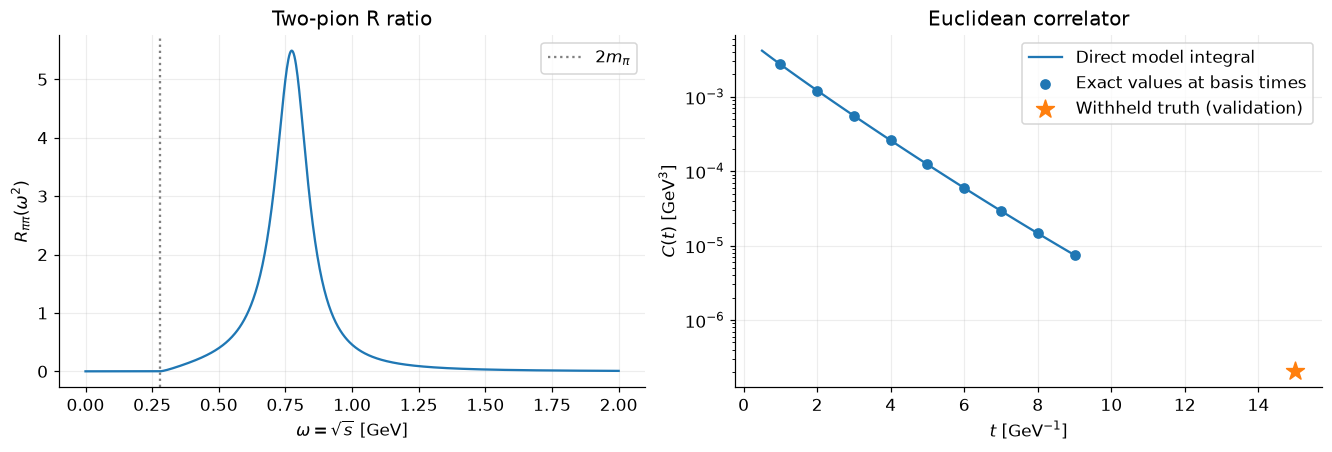

In [4]:
omega_plot = np.linspace(0, 2.0, 700)
R_plot = np.array([model.R(w**2, numerics=PLOT_NUMERICS) for w in omega_plot])
t_plot = np.linspace(0.5, 9, 120)
C_plot = np.asarray(forward_correlator(t_plot, numerics=PLOT_NUMERICS), dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(omega_plot, R_plot, color="tab:blue")
axes[0].axvline(float(model.domain[0]), color="0.5", ls=":", label=r"$2m_\pi$")
axes[0].set(xlabel=r"$\omega=\sqrt{s}$ [GeV]", ylabel=r"$R_{\pi\pi}(\omega^2)$",
            title="Two-pion R ratio")
axes[0].legend()
axes[1].semilogy(t_plot, C_plot, label="Direct model integral", color="tab:blue")
axes[1].scatter(INPUT_TIMES, np.asarray(C_input, float), color="tab:blue",
                zorder=3, label="Exact values at basis times")
axes[1].scatter([TARGET_TIME], [C_truth_float], marker="*", s=150,
                color="tab:orange", zorder=4, label="Withheld truth (validation)")
axes[1].set(xlabel=r"$t$ [GeV$^{-1}$]", ylabel=r"$C(t)$ [GeV$^3$]",
            title="Euclidean correlator")
axes[1].legend()
plt.show()

## Add Gaussian measurement noise

Generate **one measured correlator vector**
$C^{\rm obs}=C^{\rm true}+\epsilon$ with $\epsilon\sim\mathcal N(0,\Sigma)$.
The default covariance follows the existing two-pion example: a 0.5%
relative standard deviation and equicorrelation $r=0.95$,

$$
\sigma_i=0.005\,C(t_i),\qquad
\Sigma_{ij}=\sigma_i\sigma_j[(1-r)\delta_{ij}+r].
$$

Here $\Sigma$ is the covariance of the **measured mean vector itself**.
There is no additional division by the number of configurations or toys.
Set `CORRELATION=0.0` for independent time-slice noise.
A fixed seed makes this example reproducible, and every lambda uses the
**same draw**. The withheld $C(t_*)$ remains an exact validation reference.

In [5]:
RELATIVE_NOISE = "0.005"
CORRELATION = 0.95
NOISE_SEED = 2026
assert 0 <= CORRELATION < 1

with NUMERICS.context() as ctx:
    sigma = ctx.array(C_input) * ctx.number(RELATIVE_NOISE)
    correlation = ctx.number(str(CORRELATION))
    covariance = ctx.array([
        [sigma[i] * sigma[j] * (1 if i == j else correlation)
         for j in range(len(INPUT_TIMES))]
        for i in range(len(INPUT_TIMES))
    ])
covariance_float = np.asarray(covariance, dtype=float)
cholesky = np.linalg.cholesky(covariance_float)
rng = np.random.default_rng(NOISE_SEED)
noise = cholesky @ rng.standard_normal(len(INPUT_TIMES))
with NUMERICS.context() as ctx:
    C_noisy = ctx.array(C_input) + ctx.array(noise)

data = sp.CorrelatorData.from_arrays(
    times=INPUT_TIMES, mean=C_noisy,
    covariance=covariance, energy_unit="GeV",
)
show_table(
    ["t [GeV^-1]", "Exact C [GeV^3]", "Noisy C [GeV^3]", "Input sigma [GeV^3]"],
    [
        [t, f"{float(c):.8e}", f"{float(y):.8e}", f"{float(s):.5e}"]
        for t, c, y, s in zip(INPUT_TIMES, C_input, C_noisy, sigma)
    ],
)

| t [GeV^-1] | Exact C [GeV^3] | Noisy C [GeV^3] | Input sigma [GeV^3] |
| --- | --- | --- | --- |
| 1 | 2.71565601e-03 | 2.70488677e-03 | 1.35783e-05 |
| 2 | 1.20920507e-03 | 1.20510376e-03 | 6.04603e-06 |
| 3 | 5.53601870e-04 | 5.50186211e-04 | 2.76801e-06 |
| 4 | 2.58556342e-04 | 2.57875488e-04 | 1.29278e-06 |
| 5 | 1.22880525e-04 | 1.22488434e-04 | 6.14403e-07 |
| 6 | 5.93879849e-05 | 5.91393079e-05 | 2.96940e-07 |
| 7 | 2.91951313e-05 | 2.90706000e-05 | 1.45976e-07 |
| 8 | 1.46098680e-05 | 1.45575735e-05 | 7.30493e-08 |
| 9 | 7.44994206e-06 | 7.41854357e-06 | 3.72497e-08 |

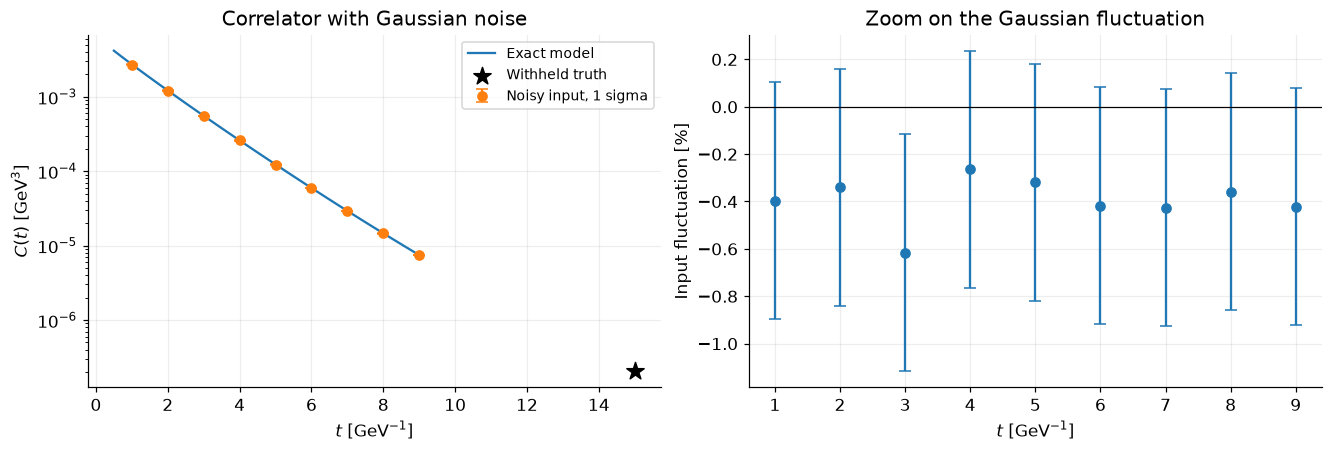

In [6]:
sigma_float = np.sqrt(np.diag(covariance_float))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].semilogy(t_plot, C_plot, label="Exact model", color="tab:blue")
axes[0].errorbar(INPUT_TIMES, np.asarray(C_noisy, float), yerr=sigma_float,
                 fmt="o", capsize=4, color="tab:orange", label="Noisy input, 1 sigma")
axes[0].scatter([TARGET_TIME], [C_truth_float], marker="*", s=140,
                color="black", label="Withheld truth")
axes[0].set(xlabel=r"$t$ [GeV$^{-1}$]", ylabel=r"$C(t)$ [GeV$^3$]",
            title="Correlator with Gaussian noise")
axes[0].legend(fontsize=9)
axes[1].errorbar(
    INPUT_TIMES, 100 * noise / np.asarray(C_input, float),
    yerr=100 * sigma_float / np.asarray(C_input, float), fmt="o", capsize=4,
)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xlabel=r"$t$ [GeV$^{-1}$]", ylabel="Input fluctuation [%]",
            title="Zoom on the Gaussian fluctuation")
plt.show()

## 
2. Reconstruct a time outside the basis

HLT finds coefficients $q_i(\lambda)$ whose kernel
$\widehat\phi_\lambda(\omega)=\sum_iq_i(\lambda)\phi_{t_i}(\omega)$
approximates $\phi_{t_*}$ at $t_*=5$. The estimator is then

$$\widehat C_\lambda(t_*)=\sum_i q_i(\lambda)C(t_i).$$

For these examples we use **identity regularization** in both notebooks,
with no additional constraints. This keeps the coefficients the same when
we add measurement noise. In the fixed GeV convention the minimized objective is

$$
(1-\lambda)\int_{\omega_0}^{\infty}
(\widehat\phi_\lambda-\phi_{t_*})^2\,d\omega+\lambda q^Tq,
\qquad 0\leq\lambda<1.
$$

Writing $A_{ij}=\int\phi_i\phi_j\,d\omega$ and
$b_i=\int\phi_i\phi_{t_*}\,d\omega$, the solve is
$[(1-\lambda)A+\lambda I]q=(1-\lambda)b$.
The numerical meaning of $\lambda$ depends on the units and regulator.
Increasing it suppresses the coefficient norm and changes the kernel mismatch;
it need not improve the model bias monotonically.

Here $t_*$ lies beyond the largest input time: this is an **extrapolation**.
Even at $\lambda=0$, its kernel generally cannot be represented exactly by
four basis functions. Recovering an input time at $\lambda=0$ would be a different,
easier test. The model parameters and $C(t_*)$ do not enter this solve, apart
from the chosen spectral threshold.

In [7]:
solver = hlt.Solver(lambda_=LAMBDAS, regulator="identity")
reconstructor = sp.Reconstructor(basis=basis, algorithm=solver, numerics=NUMERICS)
prediction = reconstructor.reconstruct(
    data, target=target, target_times=[TARGET_TIME],
)
# Remove the singleton target-time axis, retaining the lambda axis.
scan = prediction.at_time(TARGET_TIME)
assert tuple(scan.axes) == ("lambda",)
assert all(TARGET_TIME not in result.input_times for result in scan.results)

one = scan.at_lambda("1e-6")
with NUMERICS.context() as ctx:
    explicit_value = ctx.dot(ctx.array(one.coefficients), ctx.array(data.mean))
    assert abs(explicit_value - ctx.number(one.value)) < ctx.number("1e-40")
print("Example lambda:", one.coordinates["lambda"])
print("Input times:   ", one.input_times)
print("Coefficients:  ", np.asarray(one.coefficients, dtype=float))
print(f"q @ C = {float(explicit_value):.12e} GeV^3")

Example lambda: 1e-6
Input times:    (np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9))
Coefficients:   [-4.15247767e-06 -3.45203478e-04  6.45634767e-03 -1.93089541e-02
 -6.15987747e-03  1.57097913e-02  3.10129983e-02  3.76919895e-02
  3.80630991e-02]
q @ C = 5.284507958686e-08 GeV^3


The identity regulator uses only the basis, target, and lambda to choose
$q$. Thus the kernel approximations below are identical to those in the
noiseless notebook. The observed correlator changes the final contraction,
and its covariance supplies the statistical error.

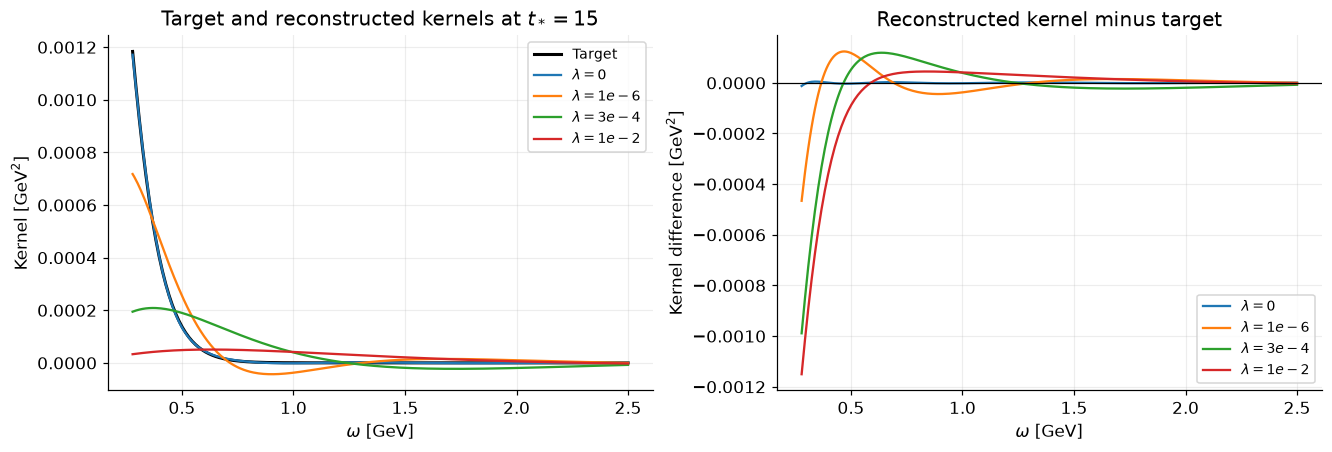

In [8]:
kernel_energies = np.linspace(float(model.domain[0]), 2.5, 300)
exact_kernel = np.asarray(basis.at_time(TARGET_TIME)(kernel_energies), float)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(kernel_energies, exact_kernel, color="black", lw=2, label="Target")
for lam in ("0", "1e-6", "3e-4", "1e-2"):
    result = scan.at_lambda(lam)
    approx = np.asarray(result.approximated_kernel(kernel_energies), float)
    axes[0].plot(kernel_energies, approx, label=fr"$\lambda={lam}$")
    axes[1].plot(kernel_energies, approx - exact_kernel, label=fr"$\lambda={lam}$")
axes[0].set(xlabel=r"$\omega$ [GeV]", ylabel=r"Kernel [GeV$^2$]",
            title=fr"Target and reconstructed kernels at $t_*={TARGET_TIME}$")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xlabel=r"$\omega$ [GeV]", ylabel=r"Kernel difference [GeV$^2$]",
            title="Reconstructed kernel minus target")
axes[0].legend(fontsize=9)
axes[1].legend(fontsize=9)
plt.show()

## 3. Signed bias and systematic uncertainty

For a spectral model $m$, compute the **signed** reconstruction bias

$$
b_\lambda^{(m)}=
\int_{\omega_0}^{\infty}
[\widehat\phi_\lambda(\omega)-\phi_{t_*}(\omega)]
\rho_2^{(m)}(\omega)\,d\omega.
$$

In the noiseless nominal model this must equal
$\widehat C_\lambda-C_{\rm truth}$. In repeated noisy experiments it is the
**expected** error, not the residual of a particular noisy draw.
The unweighted squared kernel mismatch minimized by HLT is a different quantity.

We report both $|b_\lambda^{\rm nominal}|$ and
$\sigma_{\rm sys}(\lambda)=\max_m|b_\lambda^{(m)}|$.
The latter includes the nominal model and four illustrative alternatives:
$m_\rho\pm10$ MeV, or $\Gamma_\rho\pm10\%$, one parameter at a time.
These choices demonstrate a sensitivity envelope; they are not calibrated
parameter errors, a rigorous bound, or a probabilistic one-sigma interval.
Set `deformations=None` in the estimate call to use only the nominal bias.

The same model family is reused across the lambda scan and in both notebooks.
It is separate from the Gaussian noise added to the correlator.
`estimate` integrates to infinity with adaptive quadrature and leaves the
reconstructed central values unchanged.

In [15]:
model_variations = sp.systematics.DeformationSet(
    models=(
        replace(model, m_rho="0.76526"),
        replace(model, m_rho="0.78526"),
        replace(model, gamma_rho="0.13419"),
        replace(model, gamma_rho="0.16401"),
    ),
    ids=("mass_minus_10MeV", "mass_plus_10MeV", "width_minus_10pct", "width_plus_10pct"),
    metadata={"purpose": "Illustrative parameter sensitivity; not a confidence region"},
)
report = sp.systematics.estimate(
    scan,
    reference_kernel=target,
    density=model,
    deformations=model_variations,
)

# Convert only the presentation arrays to binary64.
lambda_plot = np.asarray(LAMBDAS, dtype=float)
reconstructed = np.asarray(scan.values, dtype=float)
statistical = np.asarray(scan.statistical_errors, dtype=float)
nominal_bias = np.asarray(report.nominal_bias, dtype=float)
systematic = np.asarray(report.max_abs_bias, dtype=float)
assert np.all(systematic >= np.abs(nominal_bias))

## 4. Statistical error and separation from systematic bias

For fixed coefficients, Gaussian error propagation is exact:

$$
\sigma_{\rm stat}^2(\lambda)=q(\lambda)^T\Sigma q(\lambda),\qquad
\widehat C_\lambda^{\rm obs}-C_{\rm truth}
=b_\lambda^{\rm nominal}+q(\lambda)^T\epsilon.
$$

The statistical error uses the **full covariance**, including correlations
between times. A single observed residual mixes bias and noise; taking its
absolute value would not isolate the systematic uncertainty.
Scan points are correlated with each other because they use the same data.

With this fixed basis and identity regulator, the systematic envelope is
unchanged by the Gaussian draw. The measured central values fluctuate.
We leave the central values uncorrected and report systematic and statistical
uncertainties separately.

In [12]:
with NUMERICS.context() as ctx:
    for result, bias in zip(scan.results, report.nominal_bias):
        q = ctx.array(result.coefficients)
        propagated_variance = ctx.dot(q, ctx.array(covariance) @ q)
        observed_residual = ctx.number(result.value) - ctx.number(C_truth)
        noise_contribution = ctx.dot(q, ctx.array(noise))
        exact_prediction = ctx.dot(q, ctx.array(C_input))
        assert abs(propagated_variance - ctx.number(result.variance)) < ctx.number("1e-40")
        assert abs(observed_residual - bias - noise_contribution) < ctx.number("1e-40")
        assert abs(exact_prediction - C_truth - bias) < ctx.number("1e-40")

show_table(
    ["lambda", "Noisy reconstruction [GeV^3]", "Statistical sigma [GeV^3]",
     "|Nominal bias| [GeV^3]", "Systematic envelope [GeV^3]"],
    [
        [lam, f"{value:.8e}", f"{stat:.5e}", f"{abs(bias):.5e}", f"{sys:.5e}"]
        for lam, value, stat, bias, sys in zip(
            LAMBDAS, reconstructed, statistical, nominal_bias, systematic
        )
    ],
)
print(f"Withheld truth: {C_truth_float:.12e} GeV^3")
print("Verified: variance = q^T Sigma q and observed residual = nominal bias + q^T noise.")

| lambda | Noisy reconstruction [GeV^3] | Statistical sigma [GeV^3] | |Nominal bias| [GeV^3] | Systematic envelope [GeV^3] |
| --- | --- | --- | --- | --- |
| 0 | 9.13079212e-08 | 1.06158e-06 | 4.85048e-09 | 4.85048e-09 |
| 1e-14 | 1.15904093e-07 | 7.76093e-07 | 1.03567e-08 | 1.03567e-08 |
| 1e-12 | 1.93652426e-07 | 2.24201e-07 | 2.88472e-08 | 2.88472e-08 |
| 1e-10 | 1.77185095e-07 | 7.07839e-08 | 1.54329e-08 | 1.54329e-08 |
| 1e-8 | 9.18869847e-08 | 2.54143e-08 | 1.53821e-07 | 1.53821e-07 |
| 1e-6 | 5.28450796e-08 | 7.12487e-09 | 1.35577e-07 | 1.35577e-07 |
| 1e-5 | 4.82984282e-07 | 4.77687e-09 | 2.72255e-07 | 2.72255e-07 |
| 1e-4 | 9.77512091e-07 | 4.97810e-09 | 7.75598e-07 | 7.75598e-07 |
| 3e-4 | 9.98568440e-07 | 5.10978e-09 | 7.99041e-07 | 7.99041e-07 |
| 1e-3 | 8.62076140e-07 | 4.31451e-09 | 6.62056e-07 | 6.62056e-07 |
| 1e-2 | 4.60894423e-07 | 2.28437e-09 | 2.58452e-07 | 2.58452e-07 |
| 1e-1 | 1.17580242e-07 | 5.80767e-10 | 8.63359e-08 | 8.63359e-08 |

Withheld truth: 2.043877030604e-07 GeV^3
Verified: variance = q^T Sigma q and observed residual = nominal bias + q^T noise.


## 5. Check the statistical error with repeated Gaussian draws

Keep all coefficients fixed and generate independent repetitions of the
**whole measurement** with the same known covariance. The standard deviation
of the reconstructed values should agree with $\sqrt{q^T\Sigma q}$.
These 20,000 toys validate the propagation; they do not reduce the uncertainty
of the single measured correlator used above. Using a separate seed also
leaves that displayed measurement unchanged.

In [13]:
N_TOYS = 20_000
toy_rng = np.random.default_rng(2027)
toy_noise = toy_rng.standard_normal((N_TOYS, len(INPUT_TIMES))) @ cholesky.T
Q = np.asarray(scan.coefficients, dtype=float)  # (n_lambda, n_input_times)
toy_fluctuations = toy_noise @ Q.T
empirical_statistical = toy_fluctuations.std(axis=0, ddof=1)
# Residuals are measured relative to truth, so they include the nominal bias.
toy_residuals = nominal_bias[None, :] + toy_fluctuations
empirical_mean_residual = toy_residuals.mean(axis=0)
mean_standard_error = statistical / np.sqrt(N_TOYS)

# Allow finite Monte Carlo fluctuations in these reproducible checks.
assert np.allclose(empirical_statistical, statistical, rtol=0.04, atol=0)
assert np.all(np.abs(empirical_mean_residual - nominal_bias) < 5 * mean_standard_error)
show_table(
    ["lambda", "Analytic sigma [GeV^3]", "Toy sigma [GeV^3]", "Toy / analytic"],
    [
        [lam, f"{analytic:.5e}", f"{empirical:.5e}", f"{empirical / analytic:.4f}"]
        for lam, analytic, empirical in zip(LAMBDAS, statistical, empirical_statistical)
    ],
)

| lambda | Analytic sigma [GeV^3] | Toy sigma [GeV^3] | Toy / analytic |
| --- | --- | --- | --- |
| 0 | 1.06158e-06 | 1.07110e-06 | 1.0090 |
| 1e-14 | 7.76093e-07 | 7.82464e-07 | 1.0082 |
| 1e-12 | 2.24201e-07 | 2.26248e-07 | 1.0091 |
| 1e-10 | 7.07839e-08 | 7.10875e-08 | 1.0043 |
| 1e-8 | 2.54143e-08 | 2.53140e-08 | 0.9961 |
| 1e-6 | 7.12487e-09 | 7.07950e-09 | 0.9936 |
| 1e-5 | 4.77687e-09 | 4.78331e-09 | 1.0013 |
| 1e-4 | 4.97810e-09 | 4.95840e-09 | 0.9960 |
| 3e-4 | 5.10978e-09 | 5.07668e-09 | 0.9935 |
| 1e-3 | 4.31451e-09 | 4.28484e-09 | 0.9931 |
| 1e-2 | 2.28437e-09 | 2.27057e-09 | 0.9940 |
| 1e-1 | 5.80767e-10 | 5.77262e-10 | 0.9940 |

## 6. Reconstruction and uncertainty versus lambda

On the left, error bars are the propagated **one-sigma statistical error**
of the noisy reconstruction; the dashed line is its expected nominal bias.
On the right, compare statistical errors, their toy validation, the absolute
nominal bias, and the systematic envelope, all relative to the withheld truth.
The envelope is a model sensitivity estimate, not a Gaussian standard deviation.
The symmetric-log horizontal axes include $\lambda=0$.

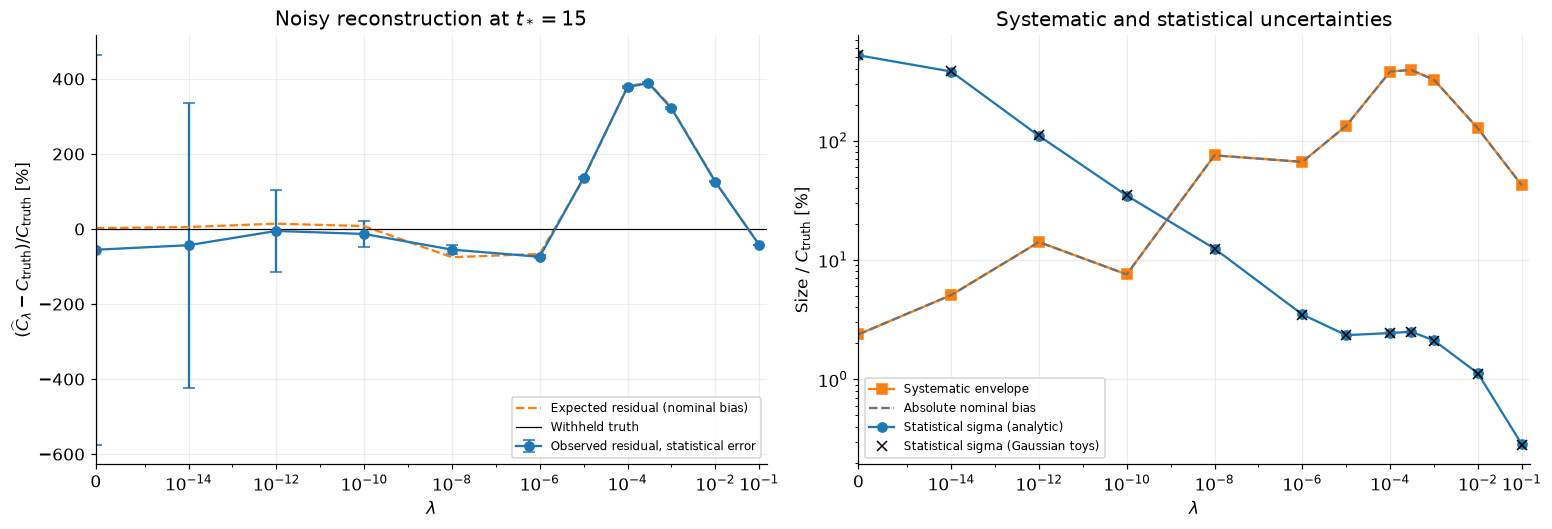

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.7), layout="constrained")
scale = 100 / C_truth_float
axes[0].errorbar(
    lambda_plot, scale * (reconstructed - C_truth_float),
    yerr=scale * statistical, fmt="o-", capsize=4,
    label="Observed residual, statistical error",
)
axes[0].plot(lambda_plot, scale * nominal_bias, "--", color="tab:orange",
             label="Expected residual (nominal bias)")
axes[0].axhline(0, color="black", lw=0.8, label="Withheld truth")
axes[0].set(
    xlabel=r"$\lambda$",
    ylabel=r"$(\widehat C_\lambda-C_{\rm truth})/C_{\rm truth}$ [%]",
    title=fr"Noisy reconstruction at $t_*={TARGET_TIME}$",
)
axes[1].plot(lambda_plot, scale * systematic, "s-", color="tab:orange",
             label="Systematic envelope")
axes[1].plot(lambda_plot, scale * np.abs(nominal_bias), "--", color="0.45",
             label="Absolute nominal bias")
axes[1].plot(lambda_plot, scale * statistical, "o-", color="tab:blue",
             label="Statistical sigma (analytic)")
axes[1].plot(lambda_plot, scale * empirical_statistical, "x", color="black",
             ms=7, label="Statistical sigma (Gaussian toys)")
axes[1].set(xlabel=r"$\lambda$", ylabel=r"Size / $C_{\rm truth}$ [%]",
            yscale="log", title="Systematic and statistical uncertainties")
for ax in axes:
    ax.set_xscale("symlog", linthresh=1e-15)
    ax.set_xlim(0, 0.15)
    ax.set_xticks([0, 1e-14,1e-12,1e-10, 1e-8, 1e-6, 1e-4, 1e-2, 1e-1])
    ax.legend(fontsize=8, loc="best")
plt.show()

For this extrapolation, regularization reduces coefficient size but can
introduce a large bias. Systematic uncertainty dominates much of the default
scan. The best lambda depends on the basis, target time, covariance, regulator,
and model family; a small error for one toy spectrum is not a universal choice.

Change `RELATIVE_NOISE`, `CORRELATION`, or the input times and rerun to study
the tradeoff. Changing `NOISE_SEED` changes the observed residual, while the
analytic statistical error and systematic envelope stay fixed in this setup.

To explore covariance regularization instead, set `regulator="covariance"`
and explicitly supply a positive `covariance_norm` to `hlt.Solver`, for example
`covariance_norm=covariance[0, 0]`. The penalty then uses
$q^T(\Sigma/\mathrm{covariance\_norm})q$; statistical propagation still uses
the original $\Sigma$. Its lambda scan and kernels will differ from the
identity-regulated examples here.